In [ ]:
# import knihoven
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from uncertainties import ufloat as uf
from scipy.optimize import curve_fit
from uncertainties import correlated_values
from pathlib import Path

# path config
downloads_dir = Path.home() / 'Downloads'
# ujistime se, ze slozka existuje (kdyby nahodou ne)
downloads_dir.mkdir(parents=True, exist_ok=True)
# output_path = downloads_dir / 'muj_graf.png'

In [ ]:
# definice funkcí

# nejistota typu A 
def unc_A(data):
    """
    Výpočet nejistoty typu A
    data : list nebo numpy array
         měření
    return : float
        nejistota typu A
    """
    data = np.array(data)
    n = len(data)

    s = np.std(data, ddof=1)
    u_A = s / np.sqrt(n)
    
    return u_A

# nacteni z df do jednotlivych arrays
def df_to_arrays(df, sloupce, od=0, do=None, dtype=float):
    if isinstance(sloupce, str):
        sloupce = [sloupce]

    chybejici = [s for s in sloupce if s not in df.columns]
    if chybejici:
        raise KeyError(f"Chybejici sloupce: {chybejici}")

    return [df[s].iloc[od:do].dropna().to_numpy(dtype=dtype) for s in sloupce]

# ufloat z aritmetickeho prumeru
def ufloat_unc_A(array):
    return uf(np.mean(array), unc_A(array))

In [ ]:
# nacteni google tabulek
sheet_id = "1cXKdaqbpzERg_syz5NUfd-MyWxmNyKs_Tjba6bure2k"
gid = "2139038384"
url = f"https://docs.google.com/spreadsheets/d/{sheet_id}/export?format=csv&gid={gid}"
df_peaks = pd.read_csv(url)

In [ ]:
# peaky pro theta
N_zavit = 1000
L_kyvadlo = 1.7
R_civka = 40.0
mu_0 = 1
g_tiha = 9.81
theta_max = np.arange(2,13)*np.pi/180
mag_moment = 1

# bez 11_min a 5_min
t_5_min = [1.004300]
U_5_min = [-0.621071]
t_11_min = [0.929500]
U_11_min = [-1.26663]
t_12_max = [0.800800]
U_12_max = [1.296594]
t_12_min = [0.821800]
U_12_min = [-1.253414]

df_peaks_theta_list = ['fm10.max_t', 'fm10.max_U', 'fm10.min_t', 'fm10.min_U', 'fm11.max_t', 'fm11.max_U', 'fm2.max_t', 'fm2.max_U', 'fm2.min_t', 'fm2.min_U', 'fm3.max_t', 'fm3.max_U', 'fm3.min_t', 'fm3.min_U', 'fm4.max_t', 'fm4.max_U', 'fm4.min_t', 'fm4.min_U', 'fm5.max_t', 'fm5.max_U', 'fm6.max_t', 'fm6.max_U', 'fm6.min_t', 'fm6.min_U', 'fm7.max_t', 'fm7.max_U', 'fm7.min_t', 'fm7.min_U', 'fm8.max_t', 'fm8.max_U', 'fm8.min_t', 'fm8.min_U', 'fm9.max_t', 'fm9.max_U', 'fm9.min_t', 'fm9.min_U']
t_10_max, U_10_max, t_10_min, U_10_min, t_11_max, U_11_max, t_2_max, U_2_max, t_2_min, U_2_min, t_3_max, U_3_max, t_3_min, U_3_min, t_4_max, U_4_max, t_4_min, U_4_min, t_5_max, U_5_max, t_6_max, U_6_max, t_6_min, U_6_min, t_7_max, U_7_max, t_7_min, U_7_min, t_8_max, U_8_max, t_8_min, U_8_min, t_9_max, U_9_max, t_9_min, U_9_min  = df_to_arrays(df_peaks, df_peaks_theta_list)
t_maxima = [t_2_max, t_3_max, t_4_max, t_5_max, t_6_max, t_7_max, t_8_max, t_9_max, t_10_max, t_11_max, t_12_max]
t_max = np.array([x[0] for x in t_maxima])
t_minima = [t_2_min, t_3_min, t_4_min, t_5_min, t_6_min, t_7_min, t_8_min, t_9_min, t_10_min, t_11_min, t_12_min]
t_min = np.array([x[0] for x in t_minima])

U_maxima = [U_2_max, U_3_max, U_4_max, U_5_max, U_6_max, U_7_max, U_8_max, U_9_max, U_10_max, U_11_max, U_12_max]
U_max = np.array([x[0] for x in U_maxima])
U_minima = [U_2_min, U_3_min, U_4_min, U_5_min, U_6_min, U_7_min, U_8_min, U_9_min, U_10_min, U_11_min, U_12_min]
U_min = np.array([x[0] for x in U_minima])

delta_t = abs(t_min - t_max)
delta_U = abs(U_max - U_min)

v_max = ((g_tiha*L_kyvadlo)**0.5)*theta_max
v_max_sin = 2*((g_tiha*L_kyvadlo)**0.5)*np.sin(theta_max/2)
a_civka = delta_t*v_max
a_civka_sin = delta_t*v_max_sin
print(f'Efektivní poloměr cívky je:\n{ufloat_unc_A(a_civka)*100:.1uP} cm\nBez aproximace sinu:\n{ufloat_unc_A(a_civka_sin)*100:.1uP} cm')
mag_moment = (U_max*(25*(5**0.5)/24)*((a_civka**2)/(N_zavit*mu_0)))/v_max
print(f'Odhad magnetického dipólového momentu je:\n'f'{ufloat_unc_A(mag_moment)*1e6:.1uP} micro Wb.m')
U_max_model = (24/(25*(5*0.5)))*((N_zavit*mu_0*mag_moment)/(a_civka**2))*v_max

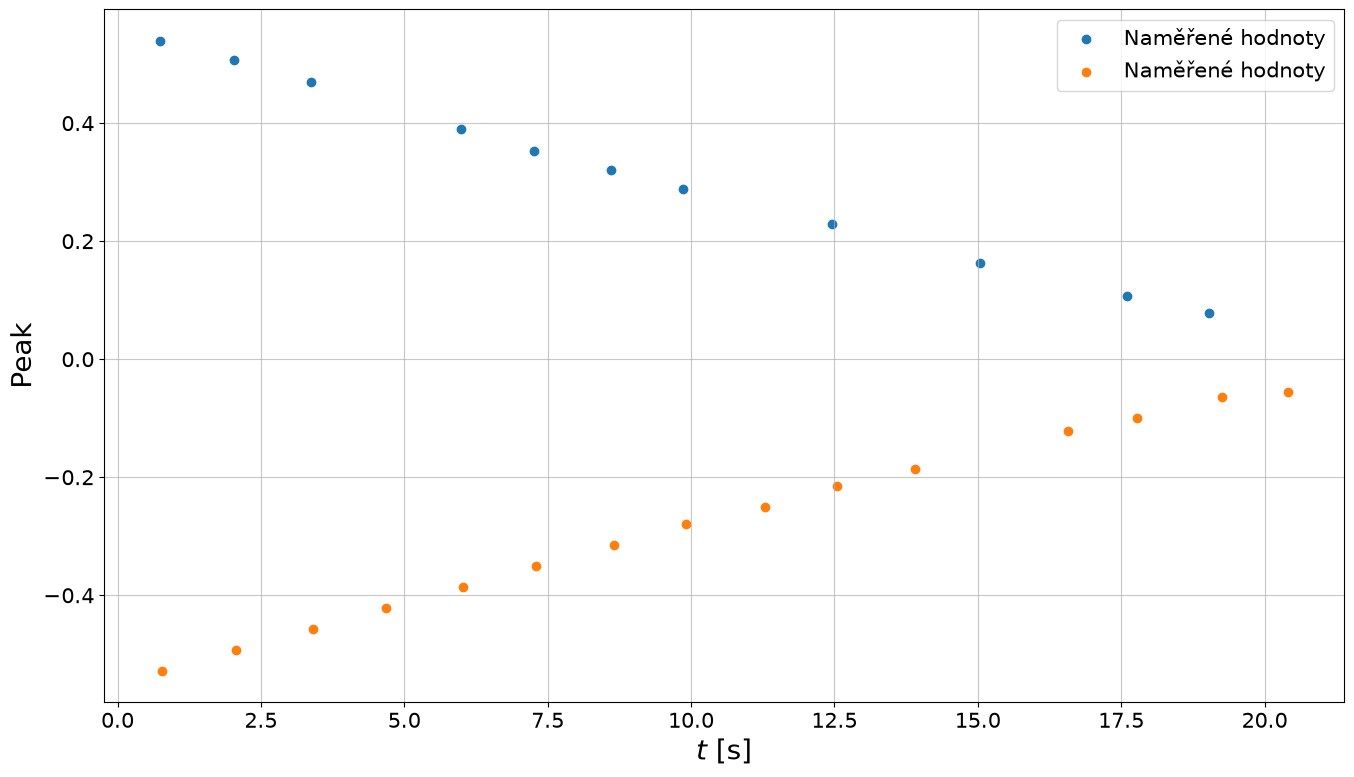

In [62]:
# tlumeni

df_peaks_peak_list = ['fmo100.max_t', 'fmo100.max_U', 'fmo100.min_t', 'fmo100.min_U', 'fmo120.max_t', 'fmo120.max_U', 'fmo120.min_t', 'fmo120.min_U', 'fmo150.max_t', 'fmo150.max_U', 'fmo150.min_t', 'fmo150.min_U', 'fmo1k.max_t', 'fmo1k.max_U', 'fmo1k.min_t', 'fmo1k.min_U', 'fmo1m.max_t', 'fmo1m.max_U', 'fmo1m.min_t', 'fmo1m.min_U', 'fmo20.max_t', 'fmo20.max_U', 'fmo20.min_t', 'fmo20.min_U', 'fmo200.max_t', 'fmo200.max_U', 'fmo200.min_t', 'fmo200.min_U', 'fmo40.max_t', 'fmo40.max_U', 'fmo40.min_t', 'fmo40.min_U', 'fmo60.max_t', 'fmo60.max_U', 'fmo60.min_t', 'fmo60.min_U', 'fmo80.max_t', 'fmo80.max_U', 'fmo80.min_t', 'fmo80.min_U', 'fmoo20.max_t', 'fmoo20.max_U', 'fmoo20.min_t', 'fmoo20.min_U']
odpor_100_max_t, odpor_100_max_U, odpor_100_min_t, odpor_100_min_U, odpor_120_max_t, odpor_120_max_U, odpor_120_min_t, odpor_120_min_U, odpor_150_max_t, odpor_150_max_U, odpor_150_min_t, odpor_150_min_U, odpor_1k_max_t, odpor_1k_max_U, odpor_1k_min_t, odpor_1k_min_U, odpor_1m_max_t, odpor_1m_max_U, odpor_1m_min_t, odpor_1m_min_U, odpor_20_max_t, odpor_20_max_U, odpor_20_min_t, odpor_20_min_U, odpor_200_max_t, odpor_200_max_U, odpor_200_min_t, odpor_200_min_U, odpor_40_max_t, odpor_40_max_U, odpor_40_min_t, odpor_40_min_U, odpor_60_max_t, odpor_60_max_U, odpor_60_min_t, odpor_60_min_U, odpor_80_max_t, odpor_80_max_U, odpor_80_min_t, odpor_80_min_U, oodpor_20_max_t, oodpor_20_max_U, oodpor_20_min_t, oodpor_20_min_U = df_to_arrays(df_peaks, df_peaks_peak_list)
oodpor_20_max_U, oodpor_20_min_U, odpor_40_max_U, odpor_40_min_U, odpor_60_max_U, odpor_60_min_U, odpor_80_max_U, odpor_80_min_U, odpor_100_max_U, odpor_100_min_U, odpor_120_max_U, odpor_120_min_U, odpor_150_max_U, odpor_150_min_U, odpor_200_max_U, odpor_200_min_U, odpor_1k_max_U, odpor_1k_min_U, odpor_1m_max_U, odpor_1m_min_U = oodpor_20_max_U*(20/(20+R_civka)), oodpor_20_min_U*(20/(20+R_civka)), odpor_40_max_U*(40/(40+R_civka)), odpor_40_min_U*(40/(40+R_civka)), odpor_60_max_U*(60/(60+R_civka)), odpor_60_min_U*(60/(60+R_civka)), odpor_80_max_U*(80/(80+R_civka)), odpor_80_min_U*(80/(80+R_civka)), odpor_100_max_U*(100/(100+R_civka)), odpor_100_min_U*(100/(100+R_civka)), odpor_120_max_U*(120/(120+R_civka)), odpor_120_min_U*(120/(120+R_civka)), odpor_150_max_U*(150/(150+R_civka)), odpor_150_min_U*(150/(150+R_civka)), odpor_200_max_U*(200/(200+R_civka)), odpor_200_min_U*(200/(200+R_civka)), odpor_1k_max_U*(1000/(1000+R_civka)), odpor_1k_min_U*(1000/(1000+R_civka)), odpor_1m_max_U*(1e6/(1e6+R_civka)), odpor_1m_min_U*(1e6/(1e6+R_civka))

fig, ax = plt.subplots(figsize=(16, 9))
ax.set_ylabel(r'Peak', fontsize=20)
ax.set_xlabel(r'$t$ [s]', fontsize=20)
ax.scatter(odpor_100_max_t, odpor_100_max_U, label='Naměřené hodnoty')
ax.scatter(odpor_100_min_t, odpor_100_min_U, label='Naměřené hodnoty')
ax.tick_params(labelsize=15)
ax.grid(True, alpha=0.7)
ax.legend(fontsize=15)
plt.savefig(downloads_dir / 'peak_pokles_20.pdf', dpi=300, bbox_inches='tight')
